# M1-B2 — Classer les avis par motif d'insatisfaction

**Mode d'emploi.** Exécute les cellules dans l'ordre. Les `___` sont à compléter. Après chaque étape, le bloc
✅ indique le résultat que tu dois obtenir (à quelques centièmes près) : s'il est très différent, relis l'étape
avant d'avancer. Les cellules sans `___` sont fournies : lis-les, elles font partie de l'apprentissage.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"   # avant tout « import keras » : Keras utilisera PyTorch

import json
import time
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
CACHE = DATA / "cache"
CACHE.mkdir(exist_ok=True)
MODELS = ROOT / "models"

MODEL_NAME = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"

## Étape 1 — Démarrer

Cette cellule télécharge le modèle d'embeddings au premier lancement (environ 470 Mo, quelques minutes) :
lance-la tout de suite, et continue à lire pendant ce temps.

In [10]:
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer(MODEL_NAME)
encoder.encode(["Le lit était très inconfortable.", "toto va bien."]).shape

(2, 384)

In [11]:
phrases = ["Le lit était très inconfortable.", "Le matelas était défoncé.", "toto va bien."]
V = encoder.encode(phrases)
encoder.similarity(V, V).numpy().round(2)   # matrice 3x3 des similarités

array([[ 1.  ,  0.36, -0.04],
       [ 0.36,  1.  ,  0.05],
       [-0.04,  0.05,  1.  ]], dtype=float32)

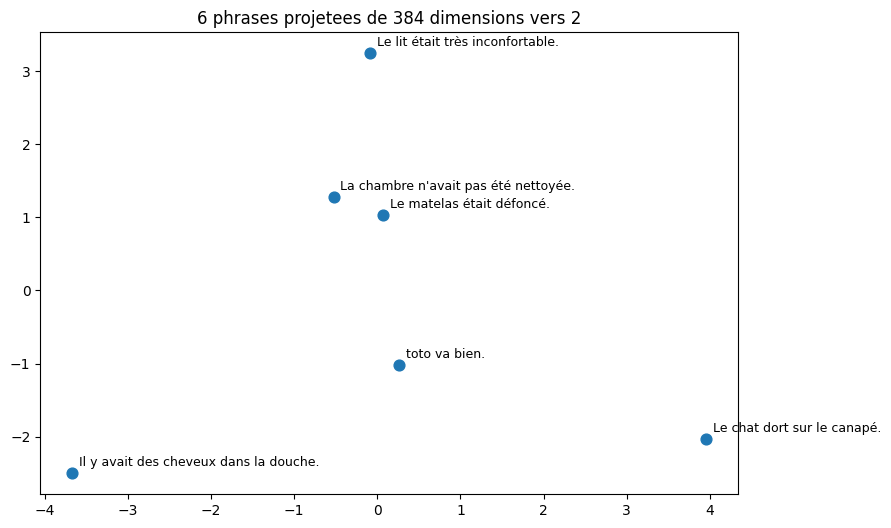

In [12]:
from sklearn.decomposition import PCA

phrases = [
    "Le lit était très inconfortable.",
    "Le matelas était défoncé.",
    "La chambre n'avait pas été nettoyée.",
    "Il y avait des cheveux dans la douche.",
    "toto va bien.",
    "Le chat dort sur le canapé.",
]
V = encoder.encode(phrases)
XY = PCA(n_components=2).fit_transform(V)   # 384 axes ramenes a 2

plt.figure(figsize=(9, 6))
plt.scatter(XY[:, 0], XY[:, 1], s=60)
for (x, y), p in zip(XY, phrases):
    plt.annotate(p, (x, y), fontsize=9, xytext=(5, 5), textcoords="offset points")
plt.title("6 phrases projetees de 384 dimensions vers 2")
plt.show()

✅ `(2, 384)` : deux phrases, 384 nombres chacune.

## Étape 2 — Explorer le corpus

- `avis_motifs.csv` : 1 200 avis de 2016, étiquetés par un LLM → pour **entraîner et tester**.
- `avis_recents.csv` : 180 avis de 2017, étiquetés à la main → **uniquement pour évaluer**, à la fin.

In [14]:
avis = pd.read_csv(DATA / "avis_motifs.csv")
recents = pd.read_csv(DATA / "avis_recents.csv")
print(len(avis), "avis,", len(recents), "avis récents")
avis["motif"].value_counts()

1200 avis, 180 avis récents


motif
proprete        189
bruit           184
equipements     144
chambre         139
restauration    138
accueil         138
reservation     112
prix             89
emplacement      67
Name: count, dtype: int64

✅ 9 motifs, de `proprete` (189 avis) à `emplacement` (67). Les classes sont **déséquilibrées** : c'est pourquoi on mesurera le F1 **macro** (chaque motif compte autant).

In [15]:
avis["texte"].str.len().describe().round()

count    1200.0
mean      170.0
std        64.0
min        28.0
25%       120.0
50%       167.0
75%       214.0
max       413.0
Name: texte, dtype: float64

In [16]:
pd.set_option("display.max_colwidth", 200)
avis.sample(20, random_state=0)[["avis_id", "texte", "motif"]]

,avis_id,texte,motif
198,199,"Nous venons souvent, mais cette fois non. Impossible de dormir à cause du bruit de la rue.",bruit
328,329,Le veilleur de nuit dormait à la réception et ne répondait pas. On nous a répondu sèchement quand nous avons signalé un problème.,accueil
45,46,Les portes claquent dans le couloir toute la nuit. On entendait la tuyauterie à chaque fois qu'un voisin tirait la chasse. On attendait mieux.,bruit
263,264,"Vacances en famille, une semaine. Tout est payant : la serviette de piscine, le transat, le coffre.",prix
621,622,"Séjour professionnel de trois nuits. Les femmes de chambre parlaient fort dans le couloir dès 8 h. La climatisation faisait un bruit d'avion toute la nuit. Les murs sont en papier, on entend tout ...",bruit
520,521,"petit-dejeuner tres decevant : pain industriel et cafe tiede. soiree au bar de l'hotel jusqu'a 2 h, la musique resonnait dans la chambre. nous avions eu un bon tarif. dommage.",bruit
186,187,"Aucun commerce ni restaurant aux alentours. Chambre au-dessus de la discothèque, nuit blanche garantie. La fenêtre n'isole absolument pas du bruit du tramway. Dommage.",bruit
987,988,Franchement pas terrible. Le personnel semblait débordé et totalement indifférent. Nous avions eu un bon tarif.,restauration
1107,1108,"Nous venons souvent, mais cette fois non. Le parking est facturé 25 € la nuit en plus. Chambre sombre avec vue sur un mur. Pas de rideaux occultants, réveillés par le soleil à 6 h. Le mobilier est...",chambre
1052,1053,Nous avions choisi cet hôtel pour fêter notre anniversaire de mariage. Moisissures au plafond de la salle de bain. Le ménage n'a pas été fait pendant trois jours malgré nos demandes. J'espère que ...,proprete


### ✏️ Ton avis sur les étiquettes du LLM

Lis les 20 avis ci-dessus. Pour combien es-tu en désaccord avec l'étiquette ? Note ici 2 ou 3 `avis_id` douteux et pourquoi.

521 -> probleme de restauration

988 -> soucis de personnel donc plutot acceuil

444 -> probleme de rangement donc plutot la chambre

## Étape 3 — La référence : TF-IDF + régression logistique

On découpe en 75 % entraînement / 25 % test, **stratifié** (chaque motif garde sa proportion dans les deux jeux).

In [ ]:
train, test = train_test_split(avis, test_size=0.25, stratify=avis["motif"], random_state=42)

def f1_macro(y_true, y_pred):
    return round(f1_score(y_true, y_pred, average="macro"), 3)

tfidf = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=2000))
tfidf.fit(train["texte"], train["motif"])
print("TF-IDF — F1 macro test :", f1_macro(test["motif"], tfidf.predict(test["texte"])))

print(len(tfidf.named_steps["tfidfvectorizer"].vocabulary_))

TF-IDF — F1 macro test : 0.911
663


✅ Environ **0,91**. C'est la référence à battre.

## Étape 4 — Les embeddings

👉 Mini-cours 11. On encode chaque avis **une seule fois** et on garde les vecteurs en cache : la fonction est fournie.

In [24]:
def encode_cached(textes, nom):
    chemin = CACHE / f"{nom}.npy"
    if chemin.exists():
        return np.load(chemin)
    vecteurs = encoder.encode(list(textes), batch_size=64, show_progress_bar=True)
    np.save(chemin, vecteurs)
    return vecteurs

E_avis = encode_cached(avis["texte"], "avis")          # une ligne par avis, dans l'ordre de `avis`
E_recents = encode_cached(recents["texte"], "recents")
E_avis.shape, E_recents.shape

((1200, 384), (180, 384))

✅ `(1200, 384)` et `(180, 384)`. Le premier lancement prend de quelques secondes à une minute ; le suivant est instantané.

⚠️ **Le piège de l'alignement.** `train` et `test` sont mélangés : il faut prendre les vecteurs **dans le même ordre**.
`avis.index` va de 0 à 1 199 dans l'ordre du fichier, comme les lignes de `E_avis` : on peut donc indexer par `train.index`.

In [33]:
E_train = E_avis[train.index]
E_test = E_avis[test.index]

emb_lr = LogisticRegression(max_iter=3000).fit(E_train, train["motif"])
print("Embeddings + logreg — F1 macro test :", f1_macro(test["motif"], emb_lr.predict(E_test)))

Embeddings + logreg — F1 macro test : 0.861


✅ Environ **0,86** : un peu moins bien que TF-IDF sur ce test. Garde ce résultat en tête pour l'étape 6.

In [34]:
pd.DataFrame({
    "tfidf": f1_score(test["motif"], tfidf.predict(test["texte"]), average=None),
    "embeddings": f1_score(test["motif"], emb_lr.predict(E_test), average=None),
}, index=sorted(avis["motif"].unique())).round(2)

,tfidf,embeddings
accueil,0.89,0.82
bruit,0.95,0.94
chambre,0.89,0.81
emplacement,0.90,0.85
equipements,0.89,0.82
prix,0.91,0.89
proprete,0.95,0.92
reservation,0.95,0.84
restauration,0.88,0.87



Le **niveau** (la valeur du F1) dit si le motif est difficile.
L'**écart** entre les deux colonnes dit s'il se reconnaît à ses mots ou à son sens.

| Niveau | Écart | Lecture | Exemple (test) |
|---|---|---|---|
| haut | nul | motif net des deux façons | `bruit` — 0,95 / 0,94 |
| bas | nul | motif réellement ambigu, les deux butent ensemble | `restauration` — 0,88 / 0,87 |
| haut | TF-IDF devant | mots-signatures efficaces, le sens ne les capte pas | `reservation` — 0,95 / 0,84 |
| — | embeddings devant | le sens aide là où les mots trompent | absent du test |

La dernière ligne n'apparaît nulle part sur le test : aucun motif ne profite des embeddings.
C'est le signe que ce jeu ne pose aucune question de compréhension — 98 % de ses phrases
figurent déjà dans l'entraînement. À vérifier sur `avis_recents`.

## Étape 5 — Un petit réseau Keras

👉 Mini-cours 12. Keras attend des classes **numérotées** : `LabelEncoder` fait la conversion.

In [47]:
import keras

keras.utils.set_random_seed(42)           # pour des résultats reproductibles
le = LabelEncoder().fit(avis["motif"])
y_train = le.transform(train["motif"])
y_test = le.transform(test["motif"])

reseau = keras.Sequential([
    keras.Input(shape=(384,)),
    keras.layers.Dense(128, activation="relu"),        # nombre de neurones de la couche cachée : 64 à 256
    keras.layers.Dropout(0.3),
    keras.layers.Dense(len(le.classes_), activation="softmax"),   # une sortie par motif
])
reseau.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
reseau.summary()


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 128)            │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,441 (197.04 KB)

 Trainable params: 50,441 (197.04 KB)

 Non-trainable params: 0 (0.00 B)

In [48]:
arret = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

historique = reseau.fit(
    E_train, y_train,
    validation_split=0.2,      # train est déjà mélangé : on peut prendre ses 20 % de fin
    epochs=100, batch_size=32, verbose=0,
    callbacks=[arret],
)
print("arrêt après", len(historique.history["loss"]), "époques")

arrêt après 20 époques


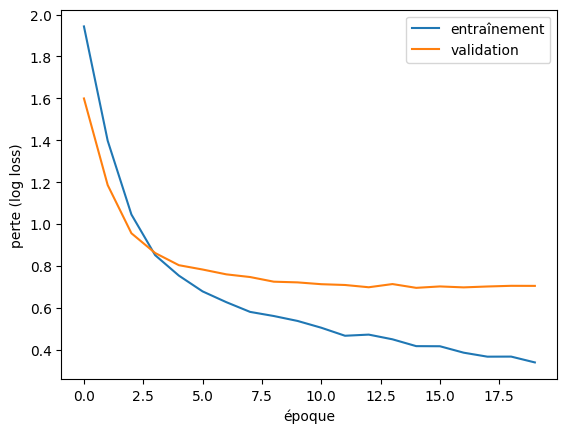

In [49]:
plt.plot(historique.history["loss"], label="entraînement")
plt.plot(historique.history["val_loss"], label="validation")
plt.xlabel("époque"); plt.ylabel("perte (log loss)"); plt.legend(); plt.show()

✅ Arrêt vers la 20e époque. La perte d'entraînement baisse toujours ; celle de validation se stabilise.

### ✏️ Que montrent tes courbes ? Pourquoi l'arrêt précoce s'est-il déclenché ?

la perte d’entraînement descend sans s’arrêter, celle de validation se stabilise vers l’époque 15 puis remonte, l’écart se creuse. L’arrêt s’est déclenché à 20 parce que la validation n’avait plus progressé depuis 15, et ce sont les poids de l’époque 15 qui ont été gardés.

In [52]:
def predict_reseau(E):
    return le.inverse_transform(reseau.predict(E, verbose=0).argmax(axis=1))

print("Keras — F1 macro test :", f1_macro(test["motif"], predict_reseau(E_test)))

Keras — F1 macro test : 0.853


✅ Environ **0,85**.

In [53]:
def essai(neurones, dropout, patience=5):
    keras.utils.set_random_seed(42)
    m = keras.Sequential([
        keras.Input(shape=(384,)),
        keras.layers.Dense(neurones, activation="relu"),
        keras.layers.Dropout(dropout),
        keras.layers.Dense(len(le.classes_), activation="softmax"),
    ])
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = m.fit(E_train, y_train, validation_split=0.2, epochs=100, batch_size=32, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(patience=patience, restore_best_weights=True)])
    pred = le.inverse_transform(m.predict(E_test, verbose=0).argmax(axis=1))
    return {"neurones": neurones, "dropout": dropout,
            "epoques": len(h.history["loss"]),
            "val_loss": round(min(h.history["val_loss"]), 3),
            "params": m.count_params(),
            "F1 test": f1_macro(test["motif"], pred)}

essais = pd.DataFrame([essai(n, d) for n in (64, 128, 256) for d in (0.0, 0.3, 0.5)])
essais.sort_values("val_loss")   # on choisit sur la validation, jamais sur le test

,neurones,dropout,epoques,val_loss,params,F1 test
2,64,0.5,35,0.677,25225,0.860
8,256,0.5,20,0.683,100873,0.870
1,64,0.3,28,0.686,25225,0.858
0,64,0.0,20,0.688,25225,0.861
3,128,0.0,20,0.690,50441,0.858
5,128,0.5,28,0.692,50441,0.857
4,128,0.3,20,0.695,50441,0.853
7,256,0.3,18,0.701,100873,0.864
6,256,0.0,15,0.703,100873,0.858


Les boutons du modèle, c’est du réglage fin. La vraie décision, c’est comment on donne le texte à lire à la machine.

## Étape 6 — Comparer et conclure

Jusqu'ici, tout a été mesuré sur le **test**, tiré du même corpus que l'entraînement.
Les **avis récents**, eux, ont été écrits par d'autres clients, avec d'autres mots. C'est le moment de vérité.

In [55]:
comparaison = pd.DataFrame([
    {"modèle": "TF-IDF + logreg",
     "F1 test": f1_macro(test["motif"], tfidf.predict(test["texte"])),
     "F1 récents": f1_macro(recents["motif"], tfidf.predict(recents["texte"]))},
    {"modèle": "embeddings + logreg",
     "F1 test": f1_macro(test["motif"], emb_lr.predict(E_test)),
     "F1 récents": f1_macro(recents["motif"], emb_lr.predict(E_recents))},
    {"modèle": "embeddings + Keras",
     "F1 test": f1_macro(test["motif"], predict_reseau(E_test)),
     "F1 récents": f1_macro(recents["motif"], predict_reseau(E_recents))},
])
comparaison

,modèle,F1 test,F1 récents
0,TF-IDF + logreg,0.911,0.389
1,embeddings + logreg,0.861,0.662
2,embeddings + Keras,0.853,0.682


### ✏️ Le classement des modèles est-il le même sur les deux jeux ? Pourquoi, à ton avis ?

*Pense aux limites de TF-IDF vues en cours.*

Non, il s'inverse. TF-IDF passe de 0,911 à 0,389, le réseau de 0,853 à 0,682.
Le meilleur sur le test devient le pire sur les avis récents.

TF-IDF travaille avec une liste de mots fixe, construite sur les avis de 2016 :
663 mots. Un mot absent de cette liste n'est pas mal interprété, il est ignoré.
Dans les avis de 2017, 39 % des mots sont dans ce cas. Le modèle décide donc sur
un peu plus de la moitié de ce qu'il lit.

Son bon score de 2016 vient de la même mécanique. J'ai vérifié que 98 % des phrases
du test figurent déjà dans l'entraînement : il n'avait pas à comprendre, juste à
reconnaître. Un compteur de mots est imbattable à ce jeu-là, et seulement à celui-là.

L'encodeur n'a pas de liste. Il place « couchage » près de « lit » même sans l'avoir
vu en 2016, parce qu'il a appris la langue ailleurs. C'est ce qui le fait tenir quand
les clients changent de mots.

Conclusion : le score sur le test ne répond pas à la question posée. Il mesure la
reconnaissance d'avis déjà vus, alors que l'outil traitera des avis qui n'existent
pas encore. Seul le jeu de 2017 mesure ça.

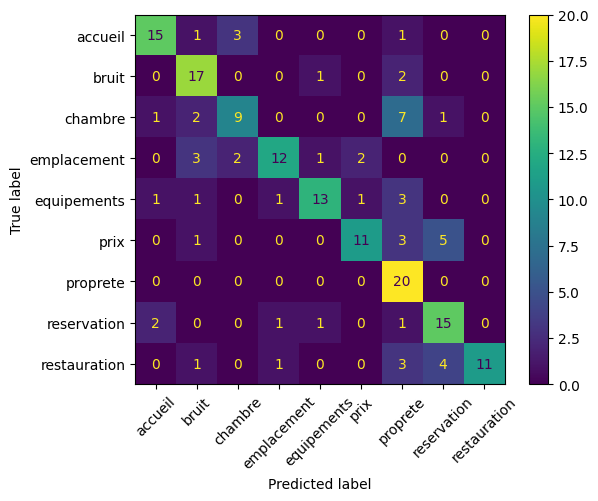

In [57]:
ConfusionMatrixDisplay.from_predictions(recents["motif"], predict_reseau(E_recents), xticks_rotation=45)
plt.show()

### Examiner 10 erreurs

La cellule affiche 10 avis du test où le réseau ne prédit pas l'étiquette du LLM.

In [61]:
erreurs = test.assign(prediction=predict_reseau(E_test)).query("motif != prediction")
print(len(erreurs), "erreurs sur", len(test))
erreurs[["avis_id", "texte", "motif", "prediction"]].head(10)

42 erreurs sur 300


,avis_id,texte,motif,prediction
422,423,"L'emplacement est pourtant idéal. La salle de bain n'avait pas de porte, aucune intimité. À éviter.",restauration,chambre
1170,1171,Lit beaucoup trop petit pour deux adultes. La réceptionniste passait plus de temps sur son téléphone qu'avec les clients. Aucune aide pour monter nos valises alors que nous avions une poussette. L...,chambre,accueil
881,882,"L'accès à l'hôtel est mal indiqué, nous avons tourné une demi-heure. Le minibar est hors de prix. Prix de la chambre doublé par rapport à l'an dernier pour les mêmes prestations. Le supplément vue...",emplacement,prix
388,389,La salle de bain était propre. Le réceptionniste ne nous a même pas regardés.,accueil,proprete
154,155,Le restaurant mérite le détour. Le concierge nous a donné de mauvaises indications et s'en est moqué. Bruit des camions de livraison à 5 h du matin. Les portes claquent dans le couloir toute la nuit.,accueil,bruit
1162,1163,Week-end en couple décevant. La literie était confortable. La carte magnétique se démagnétisait tous les jours. Je déconseille.,equipements,chambre
866,867,"Vacances en famille, une semaine. Prix d'un quatre étoiles pour une prestation de deux étoiles. Pas assez de rangements, et pas un seul cintre.",chambre,prix
1094,1095,Week-end en couple décevant. Le minibar est hors de prix. Nous avons attendu 40 minutes à la réception sans aucune excuse. Vraiment dommage pour un hôtel si bien noté.,accueil,prix
944,945,quelle deception ! buffet a volonte mais de qualite cantine. on nous a repondu sechement quand nous avons signale un probleme. accueil glacial a la reception.,accueil,restauration
1180,1181,Séjour gâché. La télévision ne captait aucune chaîne. Pas d'eau chaude le matin. Dommage.,restauration,equipements


### ✏️ Pour chaque erreur : le modèle se trompe-t-il, ou l'étiquette du LLM est-elle douteuse ?

| avis_id | étiquette (LLM) | prédiction | qui a raison, selon toi ? |
|---|---|---|---|
| 423 | restauration | chambre | **le modèle** — l'avis ne parle que d'une salle de bain sans porte, rien sur la nourriture |
| 1171 | chambre | accueil | **le modèle** — une phrase sur le lit, trois sur le personnel |
| 882 | emplacement | prix | **le modèle** — une phrase sur l'accès, trois sur les tarifs |
| 1181 | restauration | equipements | **le modèle** — télévision et eau chaude, aucune mention de repas |
| 389 | accueil | proprete | **le LLM** — le modèle s'est accroché à « la salle de bain était propre », qui est un compliment |
| 1163 | equipements | chambre | **le LLM** — même piège, il a retenu « la literie était confortable » |
| 945 | accueil | restauration | **le LLM** — l'accueil est cité deux fois, le buffet une seule |
| 155 | accueil | bruit | discutable — une phrase sur le concierge, deux sur le bruit |
| 867 | chambre | prix | discutable — le prix est plus développé que les rangements |
| 1095 | accueil | prix | discutable — 40 minutes d'attente me semblent peser plus que le minibar |

**Bilan.** Sur 10 erreurs, 4 n'en sont pas : l'étiquette du LLM est fausse et le modèle a
raison. 3 sont de vraies erreurs. 3 portent sur des avis à deux motifs, où la consigne du
motif unique rend l'arbitrage subjectif.

Les 3 vraies erreurs suivent le même schéma : le modèle a retenu une phrase **positive**
glissée dans l'avis. Il repère le thème dont on parle, pas le jugement porté. « La salle de
bain était propre » et « la salle de bain était sale » le poussent tous les deux vers
`proprete`. C'est une limite de fond, pas un défaut de réglage : rien dans l'entraînement
ne lui apprend à distinguer une plainte d'un compliment.

Le taux réel d'erreur du modèle est donc plus bas que les 42/300 affichés, puisqu'une partie
de ces erreurs est imputable aux étiquettes. Ça rejoint ce que j'avais noté en tâche 2, où
3 des 20 avis lus me semblaient mal étiquetés.

## Sauvegarder le modèle retenu

In [ ]:
choix = reseau            # ou emb_lr : à toi de choisir, et de le justifier dans la synthèse

MODELS.mkdir(exist_ok=True)
reseau.save(MODELS / "motifs.keras")
(MODELS / "motifs_info.json").write_text(json.dumps({
    "model_name": "motifs",
    "trained_on": date.today().isoformat(),
    "embedding_model": MODEL_NAME,
    "classes": list(le.classes_),   # l'ordre des sorties du réseau : indispensable pour s'en servir
}, indent=2, ensure_ascii=False), encoding="utf-8")
sorted(p.name for p in MODELS.iterdir())

['motifs.keras', 'motifs_info.json']

In [64]:
info = json.loads((MODELS / "motifs_info.json").read_text(encoding="utf-8"))
modele = keras.models.load_model(MODELS / "motifs.keras")

essai = ["La chambre n'avait pas été nettoyée.", "Impossible de dormir, musique jusqu'à 3 h."]
for txt, p in zip(essai, modele.predict(encoder.encode(essai), verbose=0)):
    print(f"{info['classes'][p.argmax()]:<13} {p.max():.0%}   {txt}")

proprete      81%   La chambre n'avait pas été nettoyée.
bruit         96%   Impossible de dormir, musique jusqu'à 3 h.


## ✏️ Synthèse (10 lignes)

**Démarche.** Deux façons de transformer les avis en nombres : comptage de mots (TF-IDF)
puis embeddings. Trois classifieurs sur ces vecteurs, même découpage, même métrique.

**Comparaison.** Le classement s'inverse. TF-IDF passe de 0,911 sur le test à 0,389 sur
2017. Le réseau passe de 0,853 à 0,682. TF-IDF a une liste de 663 mots figée sur 2016, et
39 % des mots de 2017 n'y sont pas : il les ignore. Son bon score de 2016 venait du fait
que 98 % des phrases du test étaient déjà dans l'entraînement.

**Modèle retenu.** Le réseau Keras, parce qu'il tient le mieux sur les avis récents, le
seul jeu qui réponde à la question. L'écart avec la régression logistique est de 2 points,
c'est du bruit : elle ferait aussi bien et serait plus simple à déployer.

**Erreurs.** Sur 10 erreurs, 4 viennent d'une mauvaise étiquette du LLM, pas du modèle.
Les 3 vraies erreurs se ressemblent : le modèle s'accroche à une phrase positive comme
« la salle de bain était propre ». Il voit le thème, pas le jugement. Les 3 dernières sont
des avis à deux motifs. La matrice de confusion le confirme : `proprete` attrape tous les
bons avis mais se trompe une fois sur deux, c'est devenu le fourre-tout.

**Limites.** Les étiquettes viennent d'un LLM. Sur 20 avis lus, 3 me semblaient faux, donc
le modèle ne peut pas faire mieux que ce qu'il copie. Le corpus est généré à partir de 317
phrases recyclées, ce qui gonfle le score de TF-IDF. Et comme 2016 et 2017 ne partagent
aucune phrase, la chute est plus violente qu'une vraie dérive.